##**Лабораторная  работа №2**
**Цель**: Освоение навыков решения задачи классификации с использованием модели логистической регрессии. Применение методов регуляризации (L1, L2) для борьбы с переобучением. Подбор гиперпараметров модели с использованием кросс-валидации и поиска по сетке.

**Задачи работы**

1. **Загрузить и изучить датасет** `Telco Customer Churn`:
   - Ознакомиться с признаками и целевой переменной.
   - Провести предварительный анализ: распределения, корреляции, визуализации.

2. **Подготовить данные**:
   - Обработать пропуски и закодировать категориальные признаки (LableEncoder, OneHotEncoder).
   - Удалить признаки с высокой корреляцией.
   - Разделить данные на обучающую и тестовую выборки.
   - Применить стандартизацию признаков.

3. **Обучить и оценить логистическую регрессию без регуляризации**:
   - Построить базовую модель.
   - Оценить качество с помощью метрик `accuracy`, `precision`, `recall`, `f1`.
   - Построить и проанализировать матрицу ошибок.

4. **Подобрать гиперпараметры с помощью `GridSearchCV`**:
   - Изучить влияние методов регуляризации `penalty` (L1, L2), `C` и `class_weight` на модель.
   - Применить кросс-валидацию для поиска оптимальной комбинации параметров.
   - Выбрать модель с наилучшей метрикой `f1`.

5. **Оценить качество лучшей модели**:
   - Сделать предсказания на тестовой выборке.
   - Сравнить метрики с предыдущей моделью.
   - Построить и проанализировать матрицу ошибок для лучшей модели.

6. **Проанализировать важность признаков**:
   - Извлечь и визуализировать коэффициенты обученной модели.
   - Определить топ-10 самых важных признаков.
   - Сделать выводы о влиянии признаков на предсказание оттока.


**<font color="red">Обратите внимание</font> - пункты 2-5 содержат вопросы (в конце), на которые нужно ответить письменно**

In [2]:
# Ячейка для подключения библиотек - просто запустите ее

# Импорт необходимых библиотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Для работы с датасетом
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder, PolynomialFeatures
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Для загрузки датасета с Kaggle
import kagglehub

### Ссылки на документацию для всех необходимых библиотечных моделей и функций

- [pandas.read_csv](https://pandas.pydata.org/docs/stable/reference/api/pandas.read_csv.html) — загрузка данных из CSV-файла.
- [pandas.DataFrame.info](https://pandas.pydata.org/docs/stable/reference/api/pandas.DataFrame.info.html) — информация о типах данных и пропусках.
- [pandas.DataFrame.describe](https://pandas.pydata.org/docs/stable/reference/api/pandas.DataFrame.describe.html) — статистики по числовым признакам.
- [pandas.DataFrame.hist](https://pandas.pydata.org/docs/stable/reference/api/pandas.DataFrame.hist.html) — гистограммы для числовых признаков.
- [seaborn.countplot](https://seaborn.pydata.org/generated/seaborn.countplot.html) — столбчатая диаграмма для категориальных признаков.
- [seaborn.heatmap](https://seaborn.pydata.org/generated/seaborn.heatmap.html) — тепловая карта (например, для матрицы корреляций).
- [sklearn.preprocessing.LabelEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.LabelEncoder.html) — кодирование категориальных признаков в числа.
- [sklearn.preprocessing.OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) — бинарное кодирование категориальных признаков.
- [sklearn.preprocessing.StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) — стандартизация признаков.
- [sklearn.model_selection.train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) — разделение на обучающую и тестовую выборки.
- [sklearn.linear_model.LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) — модель логистической регрессии.
- [sklearn.model_selection.GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) — подбор гиперпараметров с кросс-валидацией.
- [sklearn.metrics.accuracy_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html) — метрика точности.
- [sklearn.metrics.classification_report](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html) — отчет по метрикам классификации.
- [sklearn.metrics.confusion_matrix](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html) — матрица ошибок.
- [kagglehub.dataset_download](https://github.com/Kaggle/kagglehub#python-sdk) — загрузка датасета с Kaggle.

## **1. Загрузка датасета**

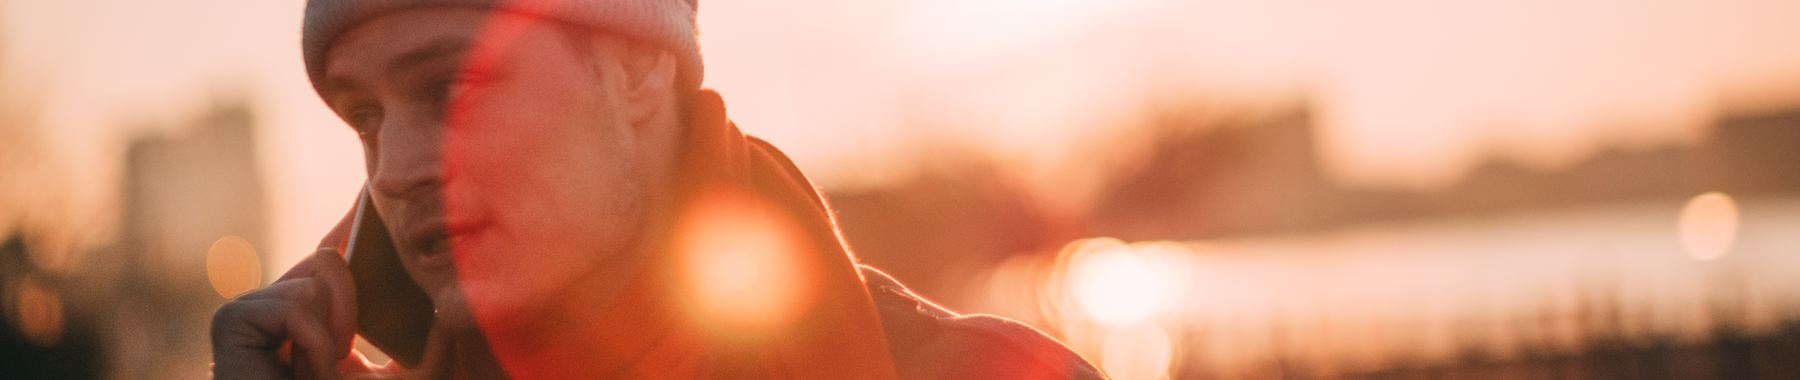

##### **Описание датасета**

**Название:** Telco Customer Churn  
**Источник:** [Kaggle Dataset](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)  
**Описание:**  
Датасет содержит информацию о клиентах телекоммуникационной компании и их поведании. Он используется для решения задачи **бинарной классификации**, где целевая переменная — **факт оттока клиента (Churn)**. Цель — обучить модель, которая сможет предсказать, уйдёт ли клиент от оператора связи.

**Целевая переменная:**
- `Churn` — ушёл ли клиент (Yes/No), бинарная категориальная переменная (после кодирования: 1 — ушёл, 0 — остался).

**Признаки:**
- `gender` — пол клиента (Male/Female), категориальный признак.
- `SeniorCitizen` — является ли клиент пенсионером (0/1), бинарный признак.
- `Partner` — наличие партнёра (Yes/No), бинарный признак.
- `Dependents` — наличие иждивенцев (Yes/No), бинарный признак.
- `tenure` — срок пользования услугами (месяцы), непрерывная величина.
- `PhoneService` — наличие телефонной услуги (Yes/No), бинарный признак.
- `MultipleLines` — наличие нескольких линий (Yes/No/No phone service), категориальный признак.
- `InternetService` — тип интернет-провайдера (DSL/Fiber optic/No), категориальный признак.
- `OnlineSecurity` — наличие онлайн-безопасности (Yes/No/No internet service), категориальный признак.
- `OnlineBackup` — наличие онлайн-бэкапа (Yes/No/No internet service), категориальный признак.
- `DeviceProtection` — наличие защиты устройства (Yes/No/No internet service), категориальный признак.
- `TechSupport` — наличие технической поддержки (Yes/No/No internet service), категориальный признак.
- `StreamingTV` — наличие стриминга ТВ (Yes/No/No internet service), категориальный признак.
- `StreamingMovies` — наличие стриминга фильмов (Yes/No/No internet service), категориальный признак.
- `Contract` — тип контракта (Month-to-month/One year/Two year), категориальный признак.
- `PaperlessBilling` — безбумажный расчёт (Yes/No), бинарный признак.
- `PaymentMethod` — способ оплаты (например, Electronic check, Mailed check), категориальный признак.
- `MonthlyCharges` — ежемесячная плата (доллары США), непрерывная величина.
- `TotalCharges` — общая сумма платежей (доллары США), непрерывная величина (иногда содержит пробелы, требует обработки).

**Пропущенные значения:** Присутствуют в столбце `TotalCharges`, где пустые значения обозначены пробелами (` `).

**Примечание:**  
Для задач машинного обучения столбец `customerID` обычно исключается, а категориальные признаки требуют кодирования (например, `OneHotEncoder` или `LabelEncoder`).

**Задание:**  
Загрузите датасет `Telco Customer Churn` с помощью библиотеки `kagglehub`.  
Для этого выполните следующие шаги:
1. Скачайте датасет, используя команду `kagglehub.dataset_download("blastchar/telco-customer-churn")`.
2. Выведите в консоль путь к скачанным файлам (его вернет метод `dataset_download`).
3. Сформируйте полный путь, добавив к пути название файла `WA_Fn-UseC_-Telco-Customer-Churn.csv`.
4. Загрузите данные из этого файла в переменную `df`, используя `pd.read_csv()`.
5. Выведите первые 5 строк датасета с помощью `df.head()`.

In [43]:
from pathlib import Path


path = kagglehub.dataset_download(
    'blastchar/telco-customer-churn',
)
file_path = Path(path) / 'WA_Fn-UseC_-Telco-Customer-Churn.csv'

file_path

PosixPath('/Users/generalsuslik/.cache/kagglehub/datasets/blastchar/telco-customer-churn/versions/1/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [44]:
df = pd.read_csv(file_path)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## **2. Предварительный анализ данных**

**Задание:**
- Выведите информацию о типах данных и наличии пропусков с помощью `df.info()`. Это покажет, сколько строк и столбцов в датасете, а также типы данных.
- Выведите размер датасета (количество строк и столбцов) с помощью `df.shape`.
- Постройте основные статистики для числовых признаков с помощью `df.describe()`. Это покажет среднее, стандартное отклонение, минимум, максимум и т.д.
- Выведите распределение целевой переменной `Churn` с помощью `df['Churn'].value_counts()`, чтобы понять, сбалансированы ли классы.
- Постройте столбчатую диаграмму (`sns.countplot`) для визуализации распределения `Churn`.


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [16]:
df.shape

(7043, 21)

In [22]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [24]:
churn = df.Churn
churn.value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

<Axes: xlabel='Churn', ylabel='count'>

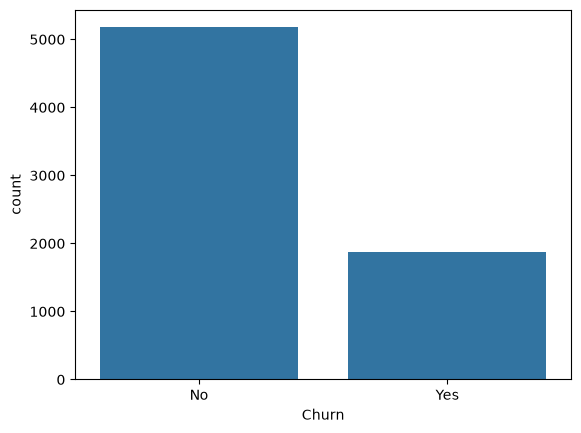

In [25]:
sns.countplot(x='Churn', data=df)

**Задание**  
- Определите и выведите список категориальных признаков, используя `df.select_dtypes(include=['object'])`.
- Проверьте наличие пропусков в датасете.
- Замените пустые строки (`" "`, `""`) на `NaN`, используя `df.replace` с заменой их на `np.nan`.
- Удалите строки, содержащие пропущенные значения, и выведите размер обновленного датасета.
- Преобразуйте столбец `TotalCharges` в числовой тип (`float`), используя `pd.to_numeric(...)`.


In [45]:
categorical_cols = df.select_dtypes(include=['object', 'string']).columns.tolist()
categorical_cols

['customerID',
 'gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'TotalCharges',
 'Churn']

In [46]:
print("Empty stuff before replacement", df.isna().sum())

df = df.replace([' ', ''], np.nan)

print("end==Empty stuff after replacement", df.isna().sum())

Empty stuff before replacement customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
end==Empty stuff after replacement customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11

In [47]:
rows_before = len(df)
shape_before = df.shape

df = df.dropna()

print("removed rows:", rows_before - len(df))
print("shape before removing rows with NaN values:", shape_before)
print("shape after removing rows with NaN values:", df.shape)

removed rows: 11
shape before removing rows with NaN values: (7043, 21)
shape after removing rows with NaN values: (7032, 21)


In [48]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges']).astype(float)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


**Задание**  
- Постройте **гистограммы** для всех **числовых** признаков с помощью `df[numeric_cols].hist()`. Не забудьте указать `figsize`, `bins` и `layout`.
- Постройте **столбчатые диаграммы** (`sns.countplot`) для всех **категориальных** признаков.

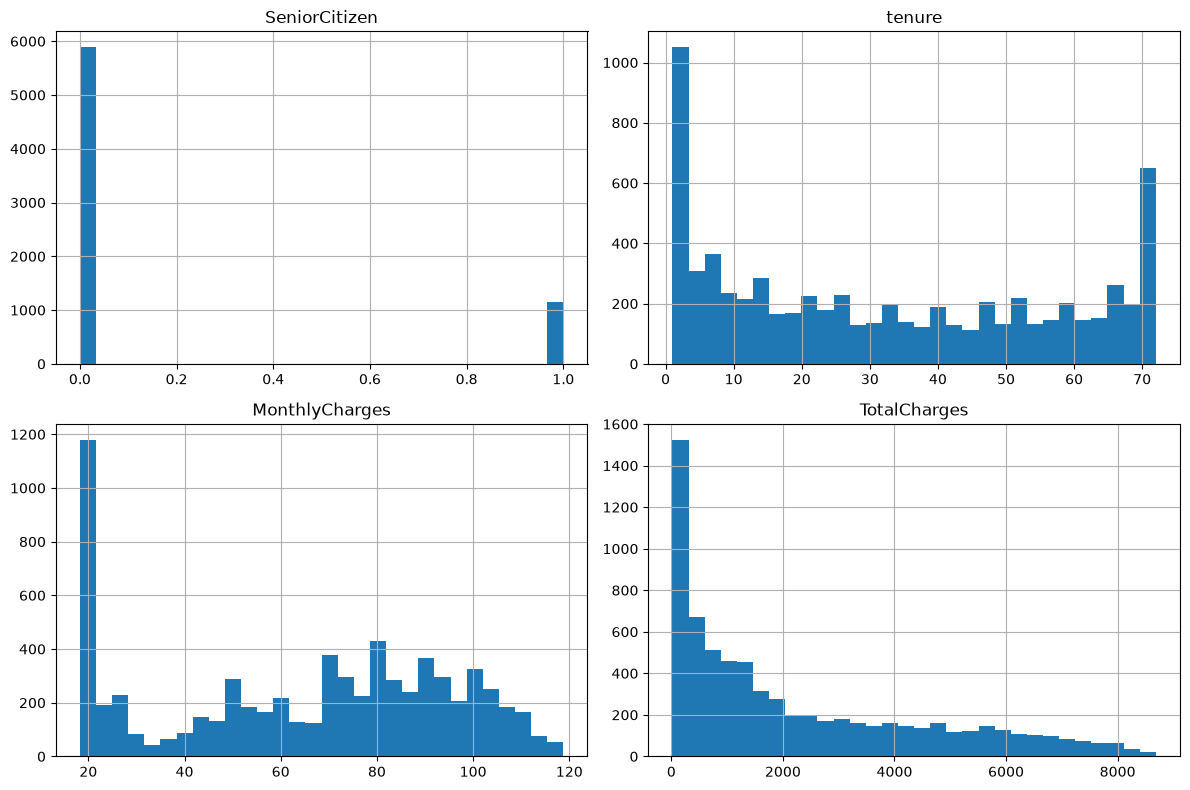

In [56]:
numeric_cols = df.select_dtypes(include=['number']).columns.tolist()

df[numeric_cols].hist(
    figsize=(12, 8),
    bins=30
)

plt.tight_layout()
plt.show()

**Ответьте на вопросы:**
- Почему дисбаланс классов при решении задачи классификации может быть проблемой?
- Сбалансированы ли классы в целевой переменной `Churn`?
- Как выбрать категориальные признаки с помощью `df.select_dtypes()`? Почему важно различать типы признаков?
- Почему пустые строки вроде `" "` или `""` могут быть проблемой? Как их можно обнаружить и исправить?
- Зачем преобразовывать столбец `TotalCharges` в числовой тип? Какие проблемы могут возникнуть, если этого не сделать?

##### **Ответы на вопросы:**
**<font color="red">(Для ввода ответа дважды щёлкните по этой ячейке, удалите красный текст и введите ответ вместо него)</font>**

## **3. Предобработка данных**

**Задание:**
- Удалите столбец `customerID`, так как он не несёт полезной информации для модели, с помощью `df.drop()`.
- Закодируйте целевую переменную `Churn` в бинарный формат (0 и 1), используя `LabelEncoder`.
- Проверьте результат, выведя первые 5 строк датасета.

**Задание:**  
Закодируйте категориальные признаки.
- Определите, какие столбцы имеют 2 уникальных значения, а какие — больше:
  - Используйте `df.select_dtypes(include=['object'])` для получения категориальных столбцов.
  - Проверьте количество уникальных значений каждого столбца с помощью `df[...].nunique()`.

- Примените `LabelEncoder` к бинарным столбцам.
- Примените `OneHotEncoder` к множественным столбцам.
- Выведите размер датасета и названия столбцов после кодирования.

**Задание:**
- Вычислите матрицу корреляций для всех признаков с помощью `df.corr()`.
- Найдите пары признаков с высокой корреляцией (значение более `0.99` по **модулю**).
- Выведите найденные пары признаков с высокой корреляцией.
- Удалите один из признаков в каждой паре с высокой корреляцией.
- Выведите размер датасета после удаления коррелирующих признаков.

**Задание:**
- Постройте матрицу корреляции для всех числовых признаков в модифицированном датасете.
- Постройте тепловую карту (`sns.heatmap`) с параметрами:
    - `annot=True` — чтобы отображать значения корреляции в ячейках.
    - `cmap='coolwarm'` — цветовая схема.
    - `figsize=(15, 10)` — размер фигуры.

**Задание:**
- Разделите датасет на признаки `X` и целевую переменную `y`:
  - Признаки `X` — это все столбцы, кроме `Churn`.
  - Целевая переменная `y` — столбец `Churn`.
- Разделите данные на обучающую и тестовую выборки:
  - Используйте `train_test_split` из `sklearn.model_selection`.
  - Установите `test_size=0.2`, чтобы 20% данных пошло на тест.
  - Установите `random_state=42` для воспроизводимости.
  - Установите `stratify=y`, чтобы сохранить пропорции классов в обеих выборках.
- Выведите размеры обучающей и тестовой выборок.

**Задание:**
- Выполните стандартизацию данных с использованием `StandardScaler` из `sklearn.preprocessing`.

**Ответьте на вопросы:**
- Зачем кодировать целевую переменную в бинарный формат?
- Зачем различать бинарные и множественные категориальные признаки? Почему здесь для них используются разные методы кодирования?
- Как `LabelEncoder` и `OneHotEncoder` изменяют структуру данных? В каких случаях какой метод предпочтительнее?
- Что показывает матрица корреляций? Почему некоторые признаки обладают корреляцией `1` (обратите внимание на названия категорий)
- Зачем использовать `stratify=y` при разделении данных? Как это влияет на распределение классов в обучающей и тестовой выборках?
- Почему стандартизация признаков важна для логистической регрессии? Как она влияет на обучение модели?

##### **Ответы на вопросы:**
**<font color="red">(Для ввода ответа дважды щёлкните по этой ячейке, удалите красный текст и введите ответ вместо него)</font>**

## **4. Обучение обычной логистической регрессии и ее оценка**

**Задание:**
- Создайте модель логистической регрессии `LogisticRegression` с параметрами:
  - `C=1000` — очень слабая регуляризация.
  - `random_state=42` — для воспроизводимости.
  - `max_iter=1000` — максимальное количество итераций.
- Обучите модель на стандартизованных обучающих данных.
- Сделайте предсказания на тестовых данных.
- Выведите метрики:
  - Точность (Accuracy) с помощью `accuracy_score`.
  - Отчет классификации, включающий другие метрики оценки качества классификации, с помощью `classification_report`.

**Задание:**
- Постройте матрицу ошибок (`confusion_matrix`) для тестовых и предсказанных значений.
- Визуализируйте матрицу с помощью `sns.heatmap`:
  - Установите `annot=True`, чтобы отображать числа в ячейках.
  - Установите `fmt='d'`, чтобы отображать целые числа.

**Ответьте на вопросы:**
- Что показывает метрика `accuracy`? Почему в задачах с дисбалансом классов она может быть недостаточной?
- Что отображает `classification_report`? Какие метрики в нём наиболее важны для оценки качества бинарной классификации?
- Что показывает матрица ошибок (`confusion_matrix`)? Как с её помощью оценить, насколько хорошо модель различает классы?
- Какие значения отображаются в ячейках матрицы ошибок? Что означает каждый из четырёх квадрантов (TP, TN, FP, FN)?
- Как визуализация матрицы ошибок помогает лучше понять поведение модели?

##### **Ответы на вопросы:**
**<font color="red">(Для ввода ответа дважды щёлкните по этой ячейке, удалите красный текст и введите ответ вместо него)</font>**

## **5. Подбор гиперпараметров для лучшей модели, ее обучение и оценка**

>Ознакомьтесь с теоретической информации прежде чем перейти к решению задачи:

**Подбор гиперпараметров с помощью `GridSearchCV`**

**Что такое `GridSearchCV`?**

`GridSearchCV` — это инструмент из библиотеки `scikit-learn`, который автоматически перебирает различные комбинации гиперпараметров модели, чтобы найти **наиболее эффективную** комбинацию.

**Зачем это нужно?**

Модель машинного обучения может давать разные результаты в зависимости от значений гиперпараметров (например, `C` - коэффициент регуляризации). Вручную перебирать все возможные комбинации бывает неудобно и долго. `GridSearchCV` делает это автоматизированно.

**Как это работает?**
- Вы задаёте **сетку параметров** — список возможных значений для каждого гиперпараметра.
- `GridSearchCV` обучает модель на каждой комбинации параметров, используя **кросс-валидацию** (например, 5-фолдную).
- В конце выбирается та комбинация, которая показала **лучший результат** (например, по метрике `f1`).

**Пример использования:**
```python
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

# Определяем сетку параметров
param_grid = [
    {'C': [0.1, 1, 10], 'penalty': ['l2']},
    {'C': [0.1, 1], 'penalty': ['l1'], 'solver': ['saga']}
]

# Создаём модель
model = LogisticRegression()

# Оборачиваем в GridSearchCV
grid_search = GridSearchCV(model, param_grid, cv=5, scoring='f1')

# Обучаем
grid_search.fit(X_train, y_train)

# Получаем лучшую модель
best_model = grid_search.best_estimator_

**Баланс классов**

В задачах классификации часто встречается **дисбаланс классов** — один класс представлен значительно чаще другого (например, 90% "нет оттока", 10% "есть отток"). В таких случаях модель может "переобучаться" на более частом классе, игнорируя редкий.

`class_weight` — это параметр моделей классификации (например, `LogisticRegression`), который позволяет задать **веса для каждого класса**.

По умолчанию веса всех классов равны 1 (`class_weight=None`), что может привести к **переобучению** на более частом классе, если в данных есть **дисбаланс** (например, 90% "нет оттока", 10% "есть отток").

Параметр `class_weight='balanced'` автоматически **уравновешивает веса классов** во время обучения: чем реже класс встречается, тем больший вес он получает. Это помогает модели лучше "обращать внимание" на редкие классы и улучшает такие метрики, как `recall` и `f1`.


**Задание:**  
Для подбора гиперпараметров используйте объект класса `GridSearchCV` из `sklearn.model_selection`.
- Определите сетку параметров `param_grid`:
  - Для `penalty='l2'`: используйте `C = [0.01, 0.1, 1, 10, 100]`.
  - Для `penalty='l1'`: используйте `C = [0.01, 0.1, 1, 10]` и `solver='saga'`.
  - Установите `class_weight='balanced'` для обеих конфигураций.
- Создайте модель `LogisticRegression` с параметрами:
  - `max_iter=1000`, `random_state=42`.
- Создайте объект `GridSearchCV`, передав:
  - Модель, сетку параметров, количество фолдов (`cv=5`), метрику (`scoring='f1'`).
- Обучите `GridSearchCV` на обучающем множестве.
- Выведите лучшие параметры (`grid_search.best_params_`) и лучшую оценку F1 (`grid_search.best_score_`).

**Задание:**
- Извлеките лучшую модель из `grid_search`, используя атрибут `best_estimator_`.
- Используя лучшую модель, сделайте предсказания на тестовых данных.
- Выведите метрики так же, как и в пункте 4:
  - Точность (Accuracy).
  - Отчет классификации.

**Задание:**
- Аналогично постройте матрицу ошибок (`confusion_matrix`) для тестовых и предсказанных значений с лучшей моделью.
- Визуализируйте матрицу с помощью `sns.heatmap`:
  - Установите `annot=True`, чтобы отображать числа в ячейках.
  - Установите `fmt='d'`, чтобы отображать целые числа.

**Задание:**

- Извлеките коэффициенты обученной модели `best_model.coef_[0]`. Эти коэффициенты показывают влияние соответствующего признака на предсказание модели.
- Определите топ-10 признаков с наибольшей важностью (по **абсолютному значению** коэффициента). Это покажет, какие признаки сильнее всего влияют на решение модели.

**Задание:**
- Постройте визуализацию важности признаков (для топ-10 по важности признаков) на основе абсолютных значений коэффициентов модели.
- Используйте столбчатую диаграмму (`sns.barplot`), где:
  - По оси X — абсолютные значения коэффициентов.
  - По оси Y — названия признаков.

**Ответьте на вопросы:**
- Что такое `GridSearchCV` и зачем он используется? Как он помогает находить оптимальные гиперпараметры?
- В чём разница между `L1` и `L2` регуляризацией?
- Почему в `GridSearchCV` используется `scoring='f1'`?
- Что означает параметр `cv=5`?
- Как `class_weight='balanced'` влияет на обучение модели? Почему это важно при дисбалансе классов?
- Как интерпретировать коэффициенты логистической регрессии? Что означает положительный и отрицательный коэффициент?
- Почему для определения важности признаков используется **абсолютное значение** коэффициента, а не само значение?
- Какие признаки оказались наиболее значимыми?

##### **Ответы на вопросы:**
**<font color="red">(Для ввода ответа дважды щёлкните по этой ячейке, удалите красный текст и введите ответ вместо него)</font>**